In [160]:
# First 10 prime numbers for plotting 
PRIMES = [2, 3, 5, 7, 11, 13, 17, 19, 23, 29] 
N_POINTS = 256

def radical_inverse(base: int, idx: int) -> float:
    assert base > 1

    digit = radical =  1 / (base)
    inverse = 0

    while idx: 
        inverse += digit * (idx % base)
        digit *= radical
        idx = idx // base

    return inverse 


def next_radical_inverse(base: int, inverse: float) -> float:
    almost_one = 1 - 1e-10
    radical = 1 / base
    next_inverse = inverse + radical
    if next_inverse < almost_one: 
        return next_inverse
    else:
        digit1 = radical
        digit2 = radical ** 2
        while(inverse + digit2 >= almost_one):
            digit1 = digit2
            digit2 *= radical
        return inverse + (digit1 - 1) + digit2


In [161]:
def halton_sequence(points: int,  primes: list[int]) -> list[int]:
    sequence = []
    for idx in range(points):
        elements = []
        for j, prime in enumerate(primes): 
            if len(sequence):
                elements.append(next_radical_inverse(prime, sequence[-1][j]))
            else:
                elements.append(radical_inverse(prime, idx))
        sequence.append(elements)
    return sequence


def hammersley_set(points: int,  primes: list[int]) -> list[int]:
    N = 1 << points 
    sequence = []
    for idx in range(points):
        elements = [idx / N]
        for j, prime in enumerate(primes): 
            if len(sequence):
                elements.append(next_radical_inverse(prime, sequence[-1][j + 1]))
            else:
                elements.append(radical_inverse(prime, idx))
        sequence.append(elements)
    return sequence


In [162]:
import matplotlib.pyplot as plt
import numpy as np

from itertools import batched

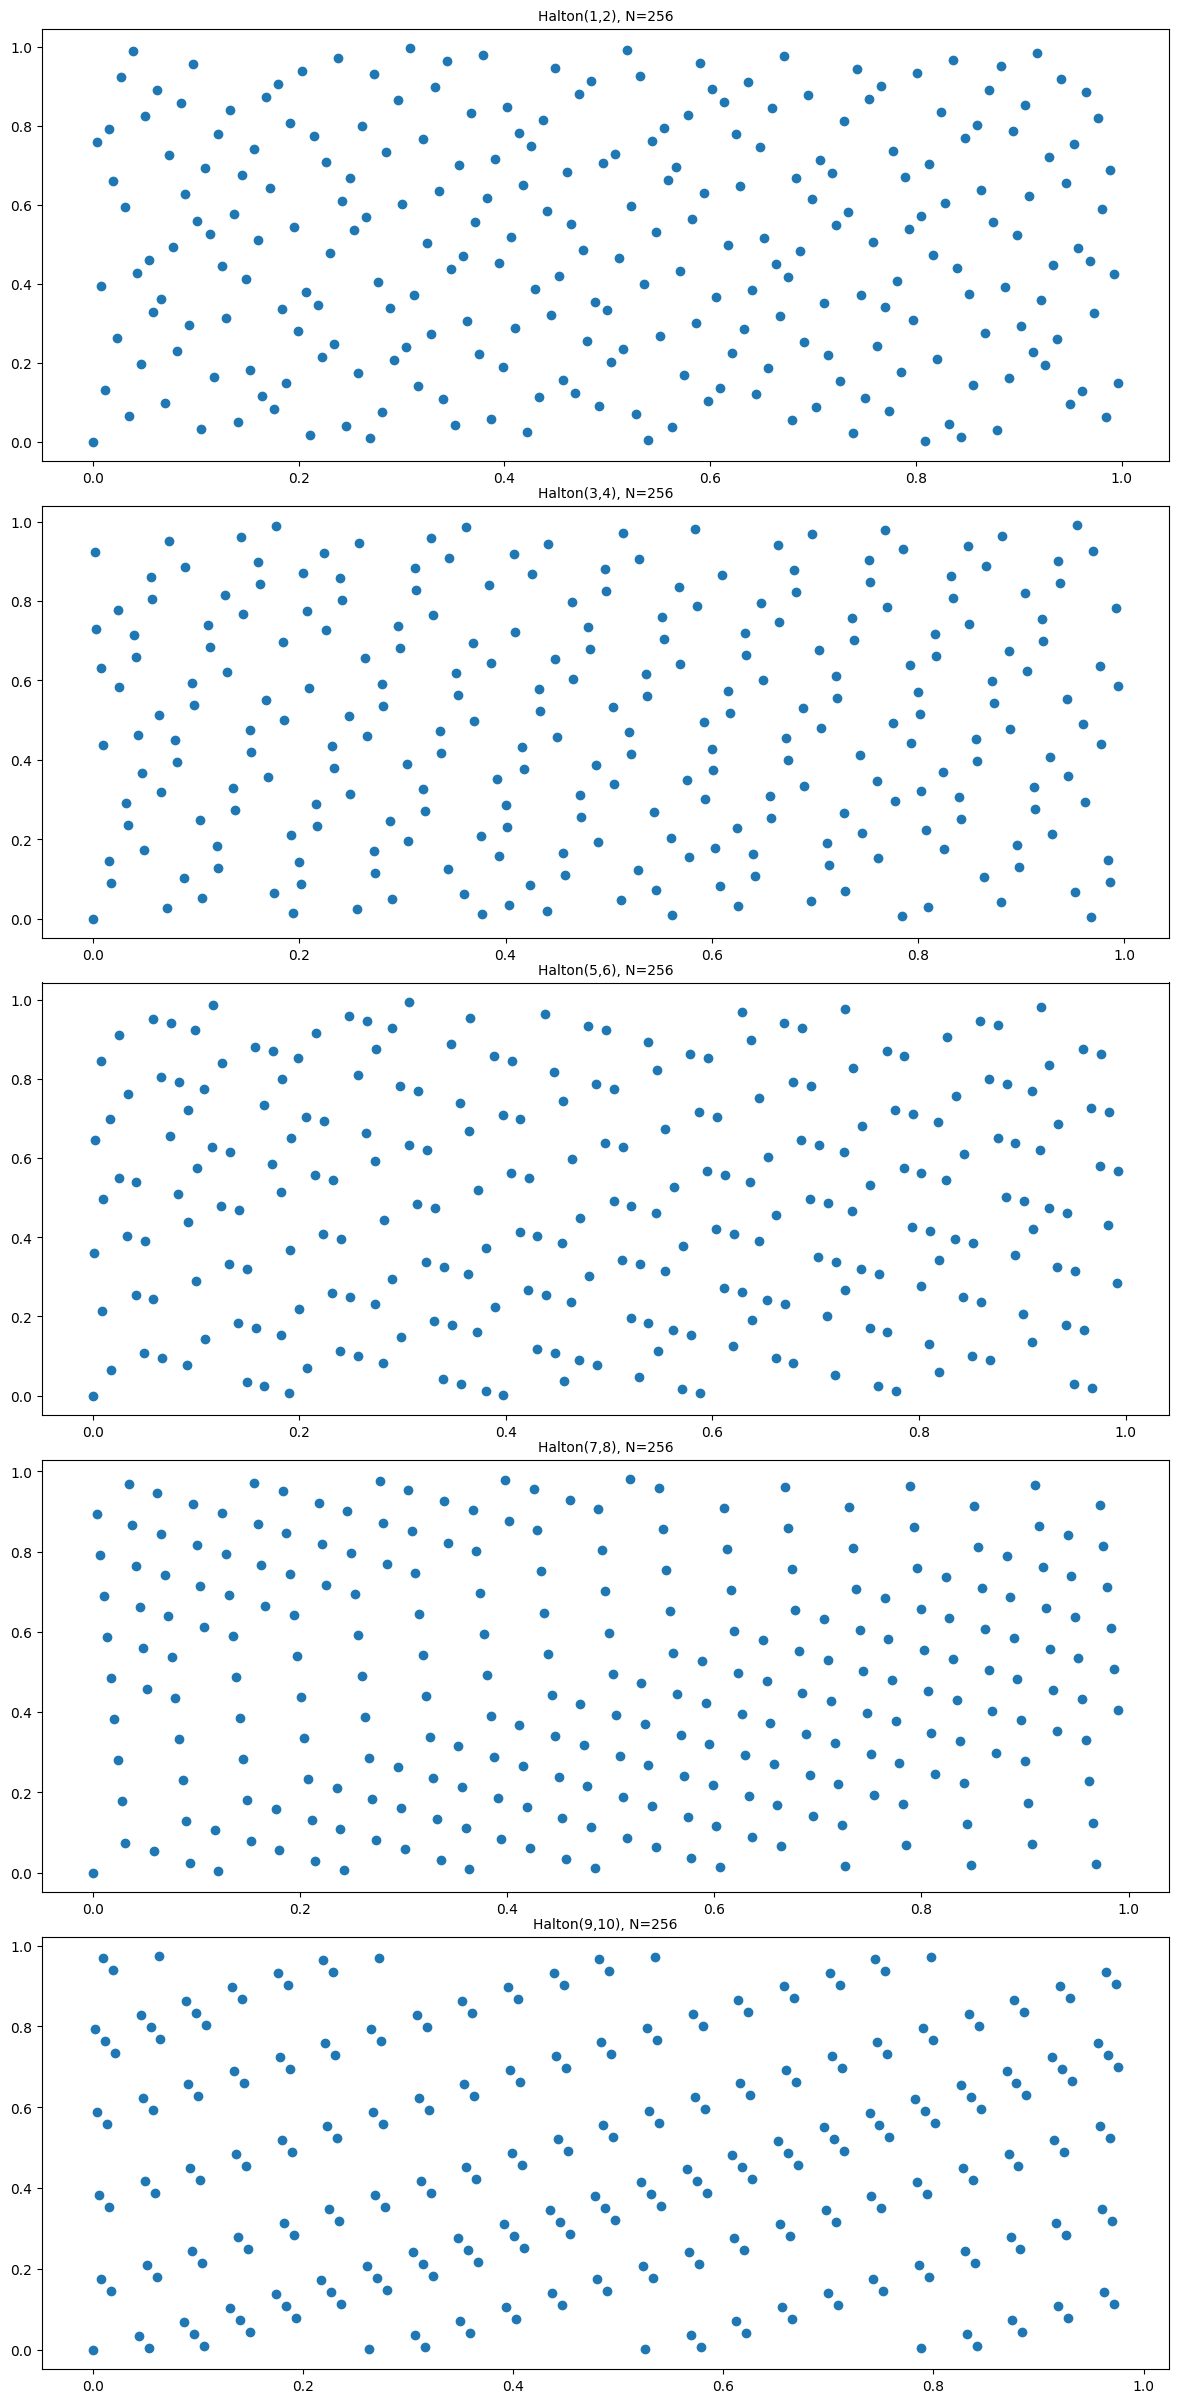

In [166]:
fig, axs = plt.subplots(5, figsize=(12, 24))
fig.tight_layout()
for idx, primes in enumerate(batched(PRIMES, n=2)):
    points = halton_sequence(N_POINTS, primes)
    x, y = list(zip(*points))
    axs[idx].scatter(x, y)
    axs[idx].set_title(f'Halton({idx * 2 + 1},{idx*2 + 2}), N={N_POINTS}', fontsize=10)


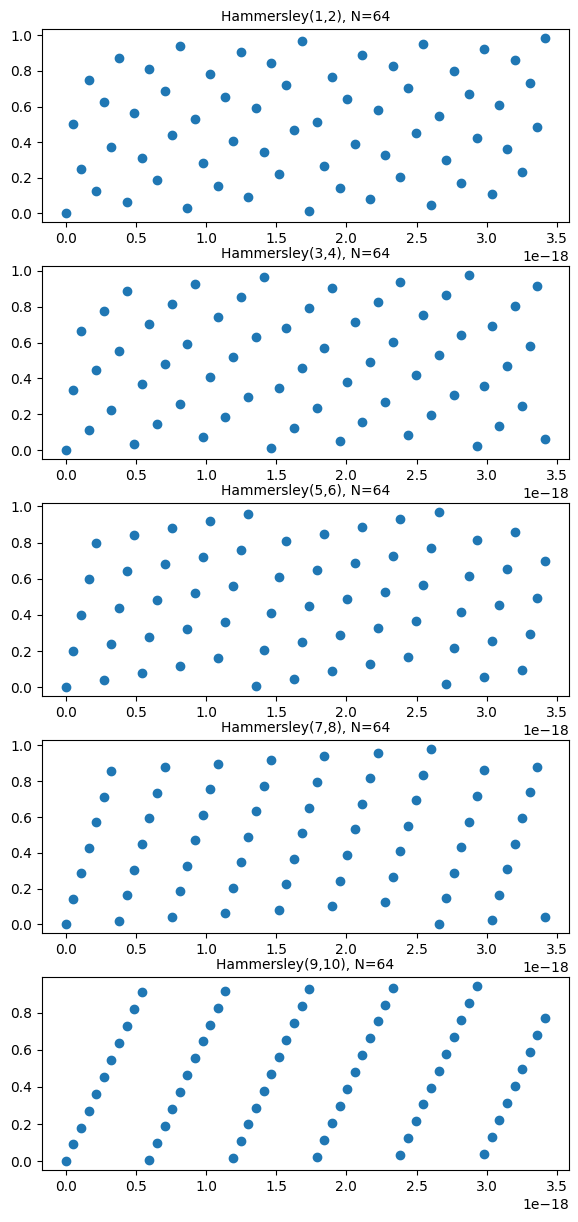

In [93]:
fig, axs = plt.subplots(5, figsize=(6, 12))
fig.tight_layout()
for idx, prime in enumerate(PRIMES[:5]):
    points = hammersley_set(N_POINTS, [prime])
    x, y = list(zip(*points))
    axs[idx].scatter(x, y)
    axs[idx].set_title(f'Hammersley({idx * 2 + 1},{idx*2 + 2}), N={N_POINTS}', fontsize=10)


In [158]:
def binary_radical_inverse(idx: int) -> float:
    inverse = 0
    exponent = 1

    while idx: 
        inverse = (inverse << 1) | (idx & 1)
        idx >>=  1
        exponent <<= 1

    return inverse / exponent

In [159]:
for idx in range(10_000):
    assert binary_radical_inverse(idx) == radical_inverse(2, idx)

print("Passed!")

Passed!
